# Data Exploration: Online Shoppers Purchase Intention

Goal: Understand the dataset before building a model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. First look

In [2]:
df = pd.read_csv("../Data/online_shoppers_intention.csv")

In [3]:
df.shape

(12330, 18)

In [4]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Findings

- The dataset has **18** columns and **12,330** rows.
- Each row is one **browsing session** on an online shop. According to the dataset authors, each session belongs to a different user, collected over one year.
- The columns fall into these groups: 
    - **Pages visited:** 
    `Administrative`,
    `Informational`,
    `ProductRelated`.
        How many pages of each type the visitor viewed.
    - **Time spent:** 
    `Administrative_Duration`,
    `Informational_Duration`,
    `ProductRelated_Duration`.
        Seconds spent on each page type.
    - **Engagement metrics:**
    `BounceRates`,
    `ExitRates`,
    `PageValues`.
        Google Analytics measures how visitors interacted with the pages.
    - **Date:**
    `Month`,
    `Weekend`,
    `SpecialDay`.
        When the visit happened, and how close it was to a holiday such as Valentine's Day.
    - **Visitor and technical info:**
    `VisitorType`,
    `OperatingSystems`,
    `Browser`,
    `Region`,
    `TrafficType`.
    - **Target:**
    `Revenue`.
        Whether the session ended in a purchase.
    
**So what:** the data describes *behaviour during a visit*, not who the customer is (no age, gender or purchase history). The model will have to predict a purchase from how someone browses, which is exactly what a shop can see in real time.

## 2. Column types

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [6]:
df.dtypes.value_counts()

int64      7
float64    7
str        2
bool       2
Name: count, dtype: int64

In [7]:
for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]: 
    print (col, sorted(df[col].unique()))

OperatingSystems [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Browser [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]
Region [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
TrafficType [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


In [8]:
for col in ["Month", "VisitorType"]:
    print(col, (df[col].unique()))

Month <StringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str
VisitorType <StringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str


In [9]:
df["Month"].value_counts()

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

In [10]:
df["Month"].value_counts(normalize=True).round(3)

Month
May     0.273
Nov     0.243
Mar     0.155
Dec     0.140
Oct     0.045
Sep     0.036
Aug     0.035
Jul     0.035
June    0.023
Feb     0.015
Name: proportion, dtype: float64

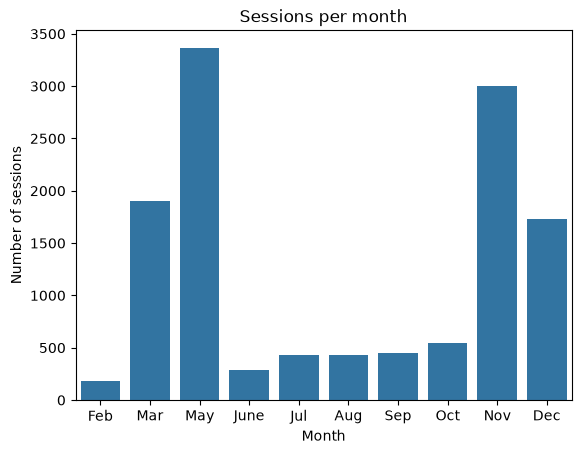

In [11]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

sns.countplot(data=df, x="Month", order=month_order)
plt.title("Sessions per month")
plt.ylabel("Number of sessions")
plt.show()

### Findings

- The 18 columns have four types:
    - **14 numeric**: 7 whole numbers (`int64`) and 7 decimals (`float64`)
    - **2 text**: `Month` and `VisitorType` (`str`)
    - **2 True/False**: `Weekend` and `Revenue` (`bool`)
- **No missing values**: every column has all 12,330 values.
- **Some "numbers" are really categories.** `OperatingSystems` (8 values), `Browser` (13), `Region` (9) and `TrafficType` (20) are stored as integers, but they are ID codes, not amounts. Region 4 is not "twice" Region 2.
- `VisitorType` has 3 values: `Returning_Visitor`, `New_Visitor` and `Other`. The dataset doesn't explain what `Other` means.
- `Month` has only **10 values**: January and April are missing, and the dataset authors don't explain why. June is written as `June`, while the other months use only 3-letter abbreviations (`Jul`, `Aug`...).
- Sessions are **very uneven across months**: May (3,364) and November (2,998) together make up over half the data, while February has only 184.

**So what**: 
- The ID-code columns must be treated as **categories** (for example with one-hot encoding). If the model treats them as numbers, it will learn meaningless patterns like "higher browser number = more likely to buy".
- `Month` and `VisitorType` are text, so they need encoding before modelling.
- The model never sees January and April, and has little data for February, so its predictions for those months will be less reliable.
- No missing values means no filling-in is needed for this dataset, but the final pipeline should still handle missing values safely in case new data has gaps.


## 3. Missing values and duplicates

In [12]:
df.isna().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(125)

In [14]:
df[df.duplicated(keep=False)].head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


### Findings

- **No missing values** in any column, confirming what `df.info()` showed
  in section 2.
- **125 rows (1.0%) are exact duplicates** of an earlier row. Including the
  first copies, 201 rows are involved.
- The duplicates all look the same kind of session:
  - 0 administrative and 0 informational pages, and usually just
    **1 product page** (118 of 125)
  - **0 seconds** spent on the site
  - `BounceRates` and `ExitRates` of 0.2, and `PageValues` of 0
  - **None of them ended in a purchase**
  - Almost all are `Returning_Visitor` (120 of 125)
- These look like **"bounce" visits**: someone opens one page and leaves
  immediately. Sessions like this have so few details that two different
  visitors can easily produce identical rows.

**So what:**
- The duplicates are most likely **real, separate visits**, not copying
  errors, so I will **keep them**. Removing them would make the data less
  like real traffic, where quick bounces are common.
- The choice has little effect anyway: removing them would only change the
  purchase rate from 15.5% to 15.6%.
- I will revisit this if the model's results look suspicious, for example
  by checking whether identical rows end up in both the training and the
  test set.

## 4. Target: Revenue

In [15]:
df["Revenue"].value_counts()

Revenue
False    10422
True      1908
Name: count, dtype: int64

In [16]:
df["Revenue"].value_counts(normalize=True).round(3)

Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64

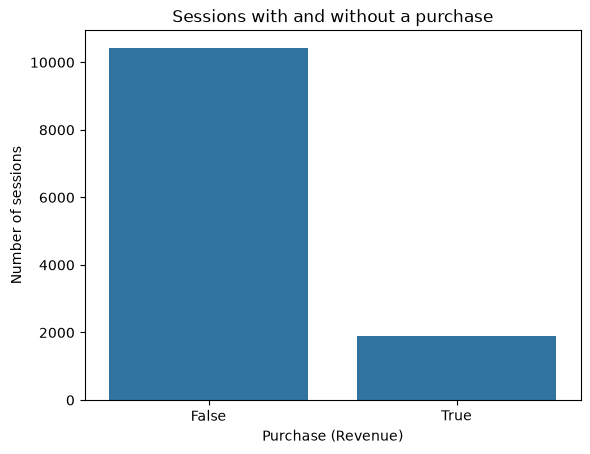

In [17]:
sns.countplot(data=df, x="Revenue")
plt.title("Sessions with and without a purchase")
plt.xlabel("Purchase (Revenue)")
plt.ylabel("Number of sessions")
plt.show()

In [18]:
baseline_accuracy = (df["Revenue"] == False).mean()
print(f"Accuracy if we always predict 'no purchase': {baseline_accuracy:.1%}")

Accuracy if we always predict 'no purchase': 84.5%


### Findings

- `Revenue` has **10,422 sessions (84.5%)** that ended up without a purchase. 
- **Only 1,908 sessions (15.5%)** ended up with a purchase.
- `baseline_accuracy` tells us that a model that always predicts "no purchase" would already be **84.5% accurate**, without learning anything.
- But it would find **0 buyers**, which makes it useless for a shop that wants to know who will buy.

**So what:**
- Accuracy is misleading here because a model can score high just by always saying "no".
- To judge the model, I will use **precision** and **recall** instead:
    - **Precision:** of the sessions the model predicts will buy, how many actually do?
    - **Recall:** of the sessions that actually bought, how many did the model find?
- When splitting the data into training and test sets, I need to keep the same 15.5% purchase rate in both (a *stratified* split), so the test set is fair.

## 5. Buyers vs non-buyers

### 5.1 Numeric features

In [19]:
df.groupby("Revenue")[["ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]].mean().round(3)

,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
Revenue,,,,,
False,28.715,1069.988,0.025,0.047,1.976
True,48.210,1876.210,0.005,0.020,27.265


In [20]:
df.groupby("Revenue")["PageValues"].median()

Revenue
False     0.000000
True     16.758134
Name: PageValues, dtype: float64

In [21]:
(df[df["Revenue"] == False]["PageValues"] == 0).mean()

np.float64(0.8856265592016888)

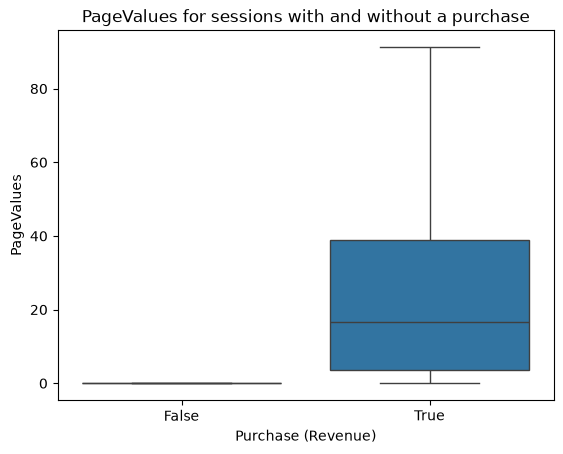

In [22]:
sns.boxplot(data=df, 
            x="Revenue", 
            y="PageValues", 
            showfliers=False)
plt.title("PageValues for sessions with and without a purchase")
plt.xlabel("Purchase (Revenue)")
plt.ylabel("PageValues")
plt.show()

#### Findings

- **PageValues** shows the biggest difference of all the features. Buyers average **27.26** vs **1.98** for non-buyers. The median for non-buyers is **0**, and **89%** of non-buyer sessions have a PageValue of exactly 0.
- Buyers view more product pages (**48.21 vs 28.71**) and spend more time on them (**1,876 s vs 1,070 s**).
- Buyers have much lower BounceRates (**about 5× lower**) and ExitRates (**about 2.4× lower**). People who plan to buy stay on the site instead of leaving early.

**So what:**
- **PageValues** will likely be the strongest feature for predicting a purchase, because it separates buyers from non-buyers the most.
- Product page counts, duration, BounceRates and ExitRates also differ clearly, so they should help the model too.
- PageValues is calculated from pages that led to purchases, so it's partly built from the target. It's still fine to use, but we should check how well the model does with and without it.

### 5.2 Visitor type and month

In [23]:
df.groupby("VisitorType")["Revenue"].mean().sort_values(ascending=False)

VisitorType
New_Visitor          0.249115
Other                0.188235
Returning_Visitor    0.139323
Name: Revenue, dtype: float64

In [24]:
df["VisitorType"].value_counts()

VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

In [25]:
df.groupby("Month")["Revenue"].mean().reindex(month_order)

Month
Feb     0.016304
Mar     0.100682
May     0.108502
June    0.100694
Jul     0.152778
Aug     0.175520
Sep     0.191964
Oct     0.209472
Nov     0.253502
Dec     0.125072
Name: Revenue, dtype: float64

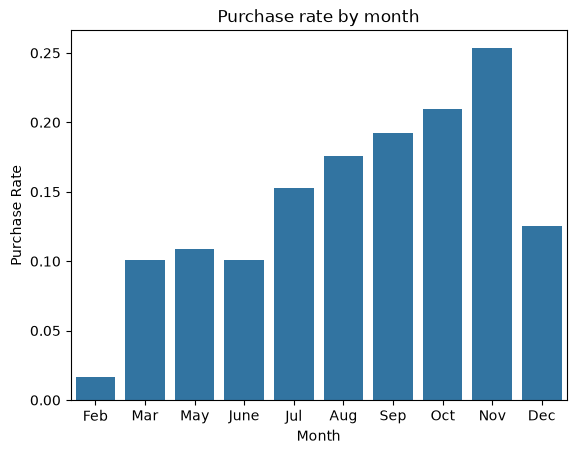

In [26]:
sns.barplot(data=df, x='Month', y="Revenue", order=month_order, errorbar=None)
plt.title("Purchase rate by month")
plt.ylabel("Purchase Rate")
plt.show()

#### Findings

- **New_Visitor** has the highest purchase rate (**24.9%**), then **Other** (**18.8%**), then **Returning_Visitor** (**13.9%**). This is surprising, since returning visitors already know the shop. It may be because Returning_Visitor is **86%** of all sessions and includes many people who come back just to browse.
- **Other** has only **85 sessions**, so its rate is not reliable. A few extra buyers would change it a lot.
- **Nov** has the highest purchase rate (**25.4%**) and **Feb** the lowest (**1.6%**, but from only 184 sessions).
- **May** has the most sessions (**3,364**) but a low purchase rate (**10.9%**). **Nov** has both many sessions (**2,998**) and the highest rate, probably because of holiday shopping (for example Black Friday).

**So what:**
- `VisitorType` and `Month` both affect the purchase rate, so they should be included in the model.
- They are text categories, so they need to be one-hot encoded before training.
- More sessions does not mean more purchases (May vs Nov), so traffic alone is not a good predictor.
- Small groups (Other, Feb) give unreliable rates, so we shouldn't trust conclusions drawn from them.

## 6. Summary

**Key findings:**
1. The data is clean: **0 missing values**. There are **125 duplicate rows**, but they are all one-page bounce visits that could really happen, and removing them barely changes the purchase rate (15.5% vs 15.6%), so they were kept.
2. Only **15.5%** of sessions end in a purchase. A model that always predicts "no purchase" would already be **84.5% accurate**, so accuracy alone is misleading.
3. **PageValues** is the strongest feature: buyers average **27.26** vs **1.98** for non-buyers, and **89%** of non-buyer sessions have a PageValue of 0.
4. Buyers view more product pages (**48 vs 29**), spend more time on them (**1,876 s vs 1,070 s**) and have much lower BounceRates (**about 5× lower**) and ExitRates (**about 2.4× lower**).
5. Purchase rate also depends on **VisitorType** and **Month**: New_Visitor (**24.9%**) and Nov (**25.4%**) have the highest rates.

**Next steps for modelling:**
- Use a **stratified 80/20 train/test split**, so both sets keep the 15.5% purchase rate.
- Judge the model with **precision and recall**, and compare against the 84.5% baseline.
- **One-hot encode** `Month`, `VisitorType` and the ID-code columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`).
- Train the model **with and without PageValues** to check how much it depends on it.